# 09 · Memory: short term and long term, as graphs
Level L2 · Part 2 · core · ~30 min · builds on 06, 08

## Goal
Keep a long conversation inside the context window, and keep a few facts about a customer across conversations. Short-term memory
is the conversation, trimmed and saved under a thread id. Long-term memory is a store, read before the answer and written after it,
with a privacy rule that refuses to save a card number.

## Why it matters
A model reads only what is in its window. A conversation that grows without a limit either overflows the window or costs more on every
turn. A customer who comes back next week should not repeat their size. But a store that keeps everything keeps the card number too.

| Without a memory design | With one |
|---|---|
| The whole conversation is resent on every turn, and grows | The old turns are trimmed, and the thread keeps the rest |
| A new chat starts blank, and the customer repeats themselves | A store keeps the facts the customer agreed to keep |
| Anything the model hears is stored | A rule refuses to store a card number, whatever the model says |

**What it makes easy:** a long conversation that stays cheap, and a customer who is not asked twice. **When you don't need it:** a
single question with no follow-up.

## The idea
**Short-term memory** is the message list of one thread. `trim_messages` keeps the newest messages that fit a token budget, and the
checkpointer saves the thread so a restart resumes it. **Long-term memory** is a store, keyed by a namespace (here, the customer).
The graph reads the store before the model answers, and writes to it after, through a node you can test without a model.

## Picture
The conversation is trimmed before the model reads it. The store is read first and written last. The amber box is the model.
`show_mermaid` is a course helper from `graph_view`: it draws a diagram from Mermaid text, right in the notebook.

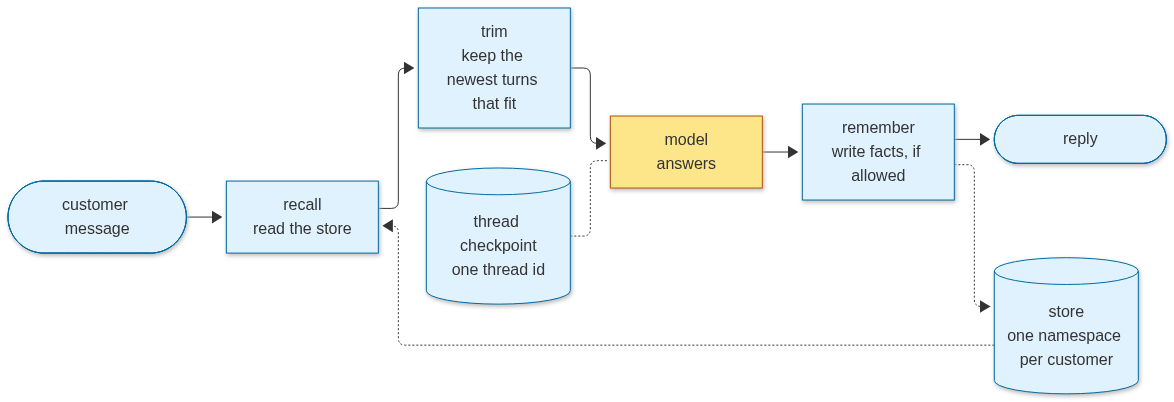

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  U(["customer message"]) --> R["recall<br/>read the store"]
  R --> T["trim<br/>keep the newest turns that fit"]
  T --> M["model<br/>answers"]
  M --> W["remember<br/>write facts, if allowed"]
  W --> E(["reply"])
  S[("store<br/>one namespace per customer")] -.-> R
  W -.-> S
  C[("thread checkpoint<br/>one thread id")] -.- M
  classDef model fill:#fde68a,stroke:#b45309
  classDef code fill:#e0f2fe,stroke:#0369a1
  class M model
  class U,R,T,W,E,S,C code
""")

## Step by step
**Step 1 · trimming the conversation (no call).** `trim_messages` keeps the newest messages within a token budget. It counts with a
simple estimate here, so the cell runs with no model; the budget is the part to learn.

In [2]:
from langchain_core.messages import AIMessage, HumanMessage, trim_messages


def estimate(messages) -> int:
    return sum(len(m.content) // 4 for m in messages)  # a rough count, for the demo only


history = []
for turn in range(1, 9):
    history += [HumanMessage(content=f"Turn {turn}: a question about my order, with some detail to make it longer."),
                AIMessage(content=f"Turn {turn}: an answer with the facts from the lookup.")]
kept = trim_messages(history, max_tokens=120, strategy="last", token_counter=estimate, start_on="human")
print(f"full history: {len(history)} messages, about {estimate(history)} tokens")
print(f"kept for the model: {len(kept)} messages, about {estimate(kept)} tokens, starting at: {kept[0].content[:30]}…")

full history: 16 messages, about 232 tokens
kept for the model: 8 messages, about 116 tokens, starting at: Turn 5: a question about my or…


**Step 2 · the privacy rule and the store (no call).** The store keeps a few facts per customer. Before anything is written, a rule
checks the fact: a card number is refused. The rule is code, so the model cannot argue its way past it. In this lesson the rule
checks for card numbers only.

In [3]:
import re
from langgraph.store.memory import InMemoryStore

store = InMemoryStore()
CARD = re.compile(r"\b(?:\d[ -]?){13,19}\b")  # a run of 13 to 19 digits: a card number, refused


def allowed_to_store(fact: str) -> tuple[bool, str]:
    if CARD.search(fact):
        return False, "refused: a card number is never stored"
    return True, "stored"


for fact in ("size M", "card 1000 0000 0000 0001"):
    ok, why = allowed_to_store(fact)
    if ok:
        store.put(("customer", "1003"), fact.replace(" ", "_"), {"fact": fact})
    print(f"{fact!r}: {why}")
print("stored for customer 1003:", [item.value["fact"] for item in store.search(("customer", "1003"))])

'size M': stored
'card 1000 0000 0000 0001': refused: a card number is never stored
stored for customer 1003: ['size M']


**Step 3 · the graph: recall, trim, answer, remember (2 model calls, one per turn).** The first turn tells the desk the customer's size.
The second turn comes in a new thread, the way a customer returns the next day. The store carries the size across the two threads.

Three course helpers appear in this step, each explained once here. `llm_replay` records the course model's answers the first time
and replays them later, so the lesson runs offline; it is not part of LangGraph. `get_llm` returns the course model (Gemini on Vertex
AI, set up from `.env`). `show_graph` draws the compiled graph and highlights the model node.

In [4]:
import llm_replay
llm_replay.start("09_memory")

import operator
from typing import Annotated
from typing_extensions import TypedDict
from langchain_core.messages import HumanMessage
from langchain_core.runnables import RunnableConfig
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.store.base import BaseStore
from llm_setup import get_llm
from graph_view import show_graph

llm = get_llm()


class MemState(TypedDict):
    messages: Annotated[list, operator.add]
    facts: list

LLM mode: replay (09_memory.yaml)


Gemini on Vertex AI · API key loaded: True


The graph has four nodes. `recall` reads the customer's facts from the store. `trim` does nothing here: the trimmed view is made
inside `answer`, so the saved thread keeps every turn. `answer` calls the model with the facts and the trimmed conversation.

In [5]:
def recall(state: MemState, config: RunnableConfig, *, store: BaseStore) -> dict:
    customer = config["configurable"]["customer_id"]
    return {"facts": [item.value["fact"] for item in store.search(("customer", customer))]}


def trim(state: MemState) -> dict:
    return {}  # the trimmed view is made inside the model node, so the saved thread keeps every turn


def answer(state: MemState) -> dict:
    context = f"Known facts about this customer: {state['facts'] or 'none'}."
    shown = trim_messages(state["messages"], max_tokens=400, strategy="last", token_counter=estimate, start_on="human")
    reply = llm.invoke([HumanMessage(content=context)] + shown)
    return {"messages": [reply]}

The fourth node, `remember`, runs after the answer. It writes a size to the store only if the rule allows it, and it reads the
customer's words from the message before the reply.

In [6]:
def remember(state: MemState, config: RunnableConfig, *, store: BaseStore) -> dict:
    customer = config["configurable"]["customer_id"]
    text = state["messages"][-2].text if len(state["messages"]) > 1 else ""  # the customer's words for this turn
    if "size" in text.lower():
        size = re.search(r"size (?:is )?([A-Za-z]{1,3})\b", text, re.IGNORECASE)
        if size:
            fact = f"size {size.group(1)}"
            ok, _ = allowed_to_store(fact)
            if ok:
                store.put(("customer", customer), fact.replace(" ", "_"), {"fact": fact})
    return {}

Now the nodes are wired in order, and the graph is compiled with a checkpointer (saves each thread) and the store (shared by all threads).

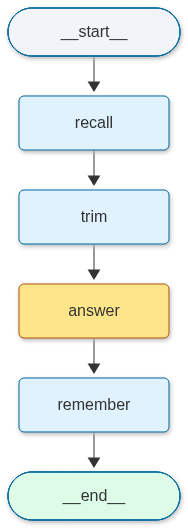

In [7]:
g = StateGraph(MemState)
g.add_node("recall", recall)
g.add_node("trim", trim)
g.add_node("answer", answer)
g.add_node("remember", remember)
g.add_edge(START, "recall").add_edge("recall", "trim").add_edge("trim", "answer")
g.add_edge("answer", "remember").add_edge("remember", END)
memory_app = g.compile(checkpointer=InMemorySaver(), store=store)
show_graph(memory_app, model_nodes=("answer",))

Turn 1 runs in thread `day-1`. The store is shared, so the next thread can read what this one saved.

In [8]:
first = memory_app.invoke({"messages": [HumanMessage(content="I am looking at a jacket. My size is M.")], "facts": []},
                          config={"configurable": {"thread_id": "day-1", "customer_id": "1003"}})
print("day 1 answer:", first["messages"][-1].text[:140])

day 1 answer: Great! Since you are looking at a jacket and we have confirmed your size is **M**, I can help you with the following:

*   **Check for fit:*


Turn 2 runs in a new thread, `day-2`, with none of the first thread's messages. Only the store links the two.

In [9]:
second = memory_app.invoke({"messages": [HumanMessage(content="Do you have a jacket in my size?")], "facts": []},
                           config={"configurable": {"thread_id": "day-2", "customer_id": "1003"}})
print("facts the second thread recalled:", second["facts"])
print("day 2 answer:", second["messages"][-1].text[:140])
llm_replay.stop()  # the last model call of this lesson

facts the second thread recalled: ['size M']
day 2 answer: Yes, I can certainly help you with that! Since I have your size on file as **M**, I have filtered our inventory to show you only the jackets


## At work
- Teams trim or summarise the conversation before each turn, and they log the token count they sent → lesson 36 (cost and latency).
- A long-term store is personal data. Teams write down what it may hold, let the customer delete it, and never store a card
  number or a password → lesson 34 (security and guardrails).
- Thread ids tie a conversation to one customer. A mix-up between threads is a privacy incident, so the id is checked on every read.

## What just happened
- **Step 1:** the 16 messages (about 232 tokens) were cut to the newest 8 (about 116 tokens), starting at Turn 5.
- **Step 2:** `size M` was stored; the card number was refused. The store for customer 1003 holds only `['size M']`.
- **Step 3:** the second thread, which had only its own message, recalled `['size M']` from the store before it answered.
- The day 2 reply says it "filtered our inventory". This lesson gives the model no inventory tool, so trust the size it used,
  not the stock claim. The model's wording is its own.

## Common mistakes
1. **Trimming by message count.** A message can be one word or a page, so a count of messages is not a budget. Leaving out the
   token counter is the easy slip, and the call fails at once.
2. **Trusting the model to decide what to remember.** A model asked to pick the facts may save a card number. The rule in Step 2
   runs in code, before any `store.put`, so the model cannot get past it.
3. **Keeping memory forever.** A fact with no expiry is a fact nobody checks. Give each fact a reason to be there.

The cell below shows mistake 1 as a real error. The exception name and its first line print; the fix comes after it.

In [10]:
try:
    trim_messages(history, max_tokens=120, strategy="last")  # no token_counter given
except TypeError as e:
    print(type(e).__name__, str(e).splitlines()[0])

TypeError trim_messages() missing 1 required keyword-only argument: 'token_counter'


The fix is the one in Step 1: pass `token_counter=estimate`, so the budget counts tokens and not messages.

## Try it
Write `keep_fact(fact)` that returns `True` for "size L" and `False` for "card 1000 0000 0000 0001". Use the `allowed_to_store` function
from Step 2. No model call is needed.

In [11]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [12]:
def keep_fact(fact: str) -> bool:
    return allowed_to_store(fact)[0]


print(keep_fact("size L"), keep_fact("card 1000 0000 0000 0001"))  # True False

True False


## Key terms
- **Short-term memory** — the message list of one thread, trimmed and saved, so the model reads only the recent part.
- **Long-term memory** — facts kept in a store, so they survive into a new thread.
- **Thread** — one conversation, named by a thread id.
- **Checkpointer** — saves a thread's state, so a restart resumes it (`InMemorySaver` here, in memory only).
- **Store** — keyed storage for long-term facts, read and written by graph nodes.
- **Namespace** — the key prefix that groups one customer's facts, such as `("customer", "1003")`.
- **Token budget** — the most tokens the model may read in one call; `trim_messages` keeps the newest messages that fit it.

## Recap
- Short-term memory is the thread, trimmed by tokens before the model reads it, and saved by the checkpointer.
- Long-term memory is a store, read before the answer, and written after it through a rule.
- The rule is code. A fact the rule refuses never reaches the store.

**Interview:** "A customer returns the next day and expects the desk to remember their size. What do you build, and what do you refuse to
store?" Strong answer: "A per-customer store that the graph reads before answering and writes after, with a rule in code that refuses
payment data. The conversation itself is trimmed by tokens and saved under the thread id."